# Marketing Campaign Performance Insights

1) Load the Dataset

In [ ]:
import pandas as pd
df=pd.read_csv('https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv')

2) Descriptive Analysis

In [ ]:
#Print the first few rows of the dataset to get an overview of the data
df.head()

,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
0,1,TechCorp,Email,Women 25-34,30 days,Facebook,5.294194,9344,62.94,Houston,English,3045,67836,5,Tech Enthusiasts,01-01-2023
1,2,Innovate Industries,Influencer,Women 35-44,45 days,Google Ads,3.326375,8783,10.67,"Washington, D.C.",German,1944,66361,4,Foodies,01-01-2023
2,3,NexGen Systems,Social Media,Women 25-34,45 days,Instagram,4.056375,9111,73.20,Miami,Spanish,3156,86240,8,Fashionistas,01-01-2023
3,4,Innovate Industries,Email,Women 25-34,45 days,Instagram,4.496375,7420,60.92,Seattle,Spanish,2388,58251,6,Foodies,01-01-2023
4,5,Data Tech Solutions,Influencer,Men 25-34,30 days,Google Ads,4.405930,2146,138.82,Chicago,English,1025,34407,5,Tech Enthusiasts,01-01-2023


In [ ]:
#Obtain the number of rows and columns in the dataset
df.shape

(22029, 16)

In [ ]:
#Get a concise summary of the dataset, including the data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22029 entries, 0 to 22028
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Campaign_ID       22029 non-null  int64  
 1   Company           22029 non-null  object 
 2   Campaign_Type     22029 non-null  object 
 3   Target_Audience   22029 non-null  object 
 4   Duration          22029 non-null  object 
 5   Channel_Used      22029 non-null  object 
 6   Conversion_Rate   22029 non-null  float64
 7   Acquisition_Cost  22029 non-null  int64  
 8   ROI               22029 non-null  float64
 9   Location          22029 non-null  object 
 10  Language          22029 non-null  object 
 11  Clicks            22029 non-null  int64  
 12  Impressions       22029 non-null  int64  
 13  Engagement_Score  22029 non-null  int64  
 14  Customer_Segment  22029 non-null  object 
 15  Date              22029 non-null  object 
dtypes: float64(2), int64(5), object(9)
memor

In [ ]:
#Generate descriptive statistics for numerical columns
df.describe()

,Campaign_ID,Conversion_Rate,Acquisition_Cost,ROI,Clicks,Impressions,Engagement_Score
count,22029.000000,22029.000000,22029.000000,22029.000000,22029.000000,22029.000000,22029.000000
mean,11015.000000,4.757232,5522.740842,182.863648,2223.807572,50610.402787,6.582323
std,6359.368876,0.960393,2597.666260,301.619721,1394.166380,28542.979123,1.458804
min,1.000000,2.015723,1000.000000,-98.300000,30.000000,1001.000000,4.000000
25%,5508.000000,4.130705,3286.000000,-4.080000,1067.000000,25804.000000,5.000000
50%,11015.000000,4.761527,5525.000000,93.650000,2088.000000,50858.000000,7.000000
75%,16522.000000,5.429335,7766.000000,247.310000,3212.000000,75165.000000,8.000000
max,22029.000000,7.469907,9999.000000,3109.790000,6887.000000,99999.000000,9.000000


Data Exploration:

In [ ]:
#Print the number of unique Campaign_ID values in the dataset
print("Number of unique Campaign_ID",df['Campaign_ID'].nunique())

Number of unique Campaign_ID 22029


In [ ]:
#List the unique values of the Location and Customer_Segment columns
df['Location'].unique()


array(['Houston', 'Washington, D.C.', 'Miami', 'Seattle', 'Chicago',
       'Los Angeles', 'Atlanta', 'Dallas', 'New York', 'San Francisco'],
      dtype=object)

In [ ]:
df['Customer_Segment'].unique()

array(['Tech Enthusiasts', 'Foodies', 'Fashionistas',
       'Outdoor Adventurers', 'Health & Wellness'], dtype=object)

In [ ]:
#Count the occurrences of each category in the Campaign_Type and Channel_Used and columns
df['Campaign_Type'].value_counts()

,count
Campaign_Type,
Display,4450
Search,4441
Social Media,4412
Email,4388
Influencer,4338


In [ ]:
df['Channel_Used'].value_counts()

,count
Channel_Used,
Facebook,3742
Google Ads,3694
Website,3688
Instagram,3649
YouTube,3632
Email,3624


# Exploratory Data Analysis (EDA) and Visualization

# 1.Campaign Performance:

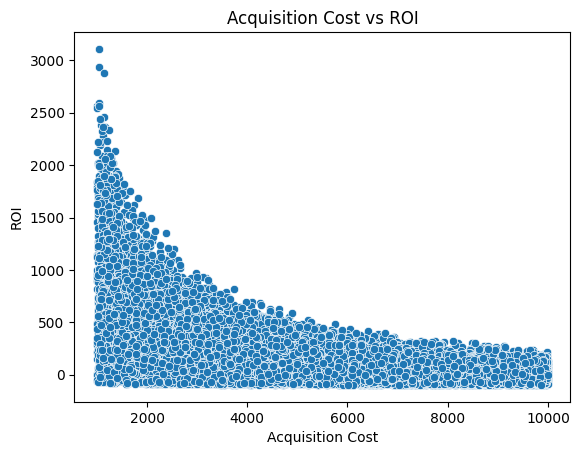

In [ ]:
# Scatter Chart-Acquisition Cost vs ROI
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(data=df, x='Acquisition_Cost', y='ROI')

plt.title('Acquisition Cost vs ROI')
plt.xlabel('Acquisition Cost')
plt.ylabel('ROI')

plt.show()

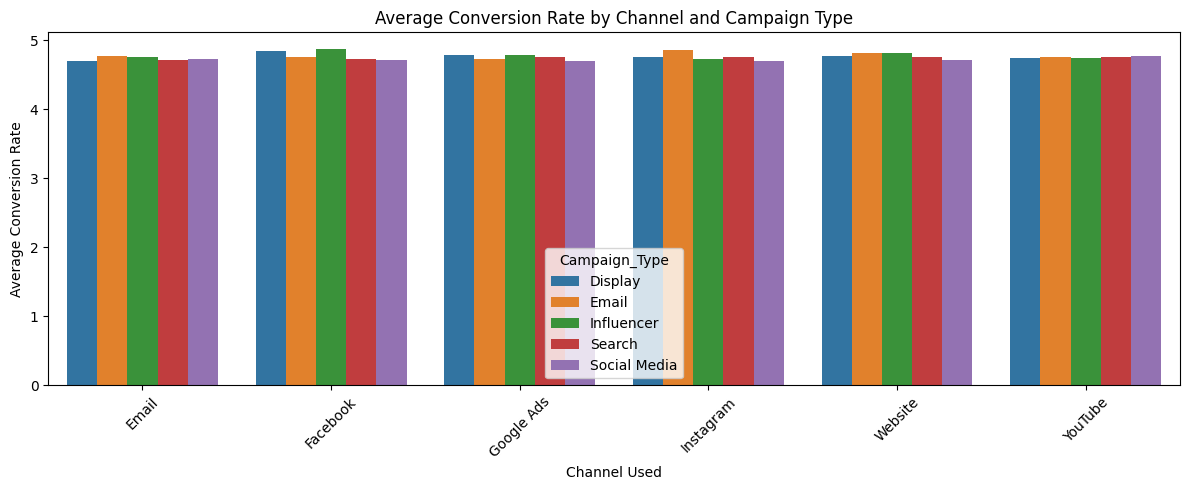

In [ ]:
#Bar chart-Average Conversion Rate by Channel and Campaign Type
Avg_convo_rate = df.groupby(['Channel_Used', 'Campaign_Type'])['Conversion_Rate'].mean().reset_index()
plt.figure(figsize=(12, 5))

sns.barplot(
    data=Avg_convo_rate,
    x='Channel_Used',
    y='Conversion_Rate',
    hue='Campaign_Type'
)

plt.xlabel('Channel Used')
plt.ylabel('Average Conversion Rate')
plt.title('Average Conversion Rate by Channel and Campaign Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

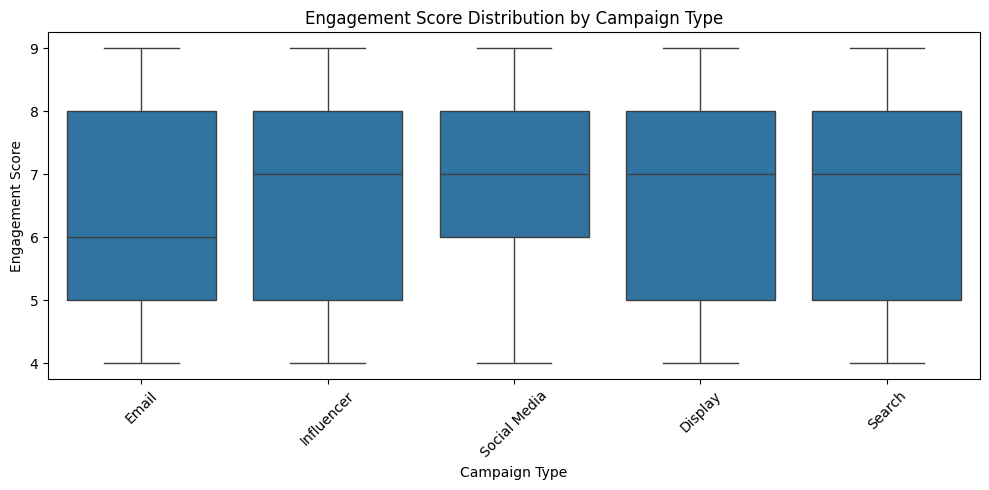

In [ ]:
#Boxplot-Engagement Score Distribution by Campaign Type
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x='Campaign_Type', y='Engagement_Score')

plt.xlabel('Campaign Type')
plt.ylabel('Engagement Score')
plt.title('Engagement Score Distribution by Campaign Type')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

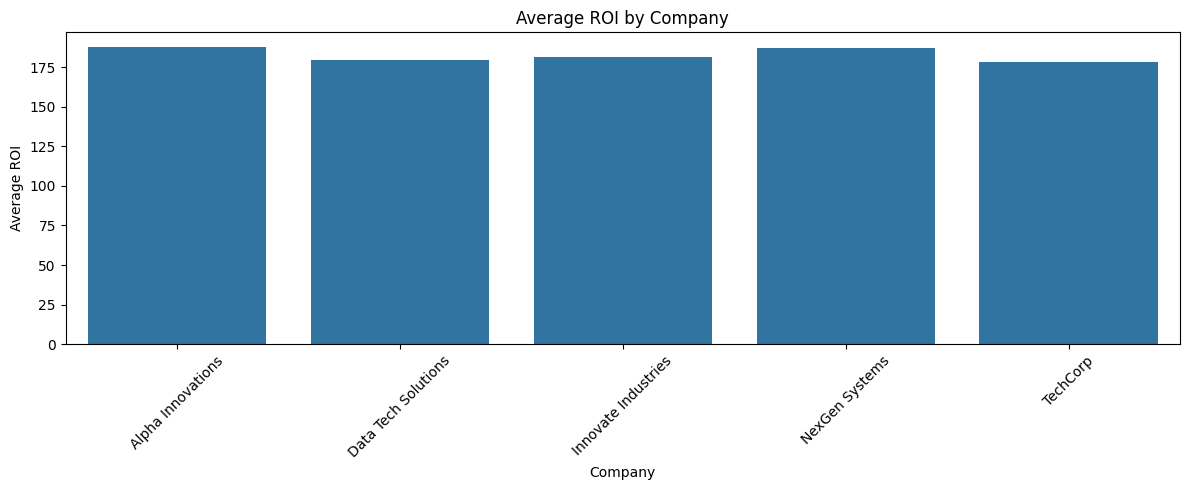

In [ ]:
# bar chart -Avg ROI by company
avg_roi = df.groupby('Company')['ROI'].mean().reset_index()

plt.figure(figsize=(12, 5))

sns.barplot(data=avg_roi, x='Company', y='ROI')

plt.title('Average ROI by Company')
plt.xlabel('Company')
plt.ylabel('Average ROI')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

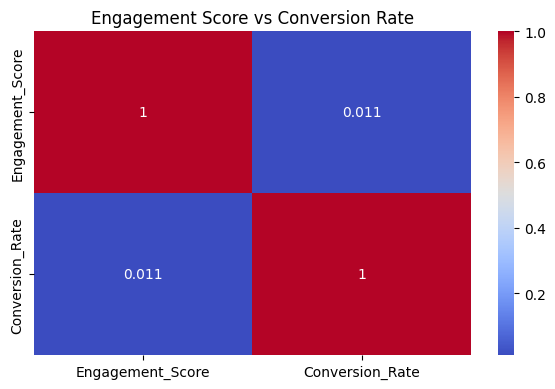

In [ ]:
#Heatmap-Engagement Score vs Conversion Rate
corr = df[['Engagement_Score', 'Conversion_Rate']].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title('Engagement Score vs Conversion Rate')
plt.tight_layout()
plt.show()

# 2.Customer Segmentation:

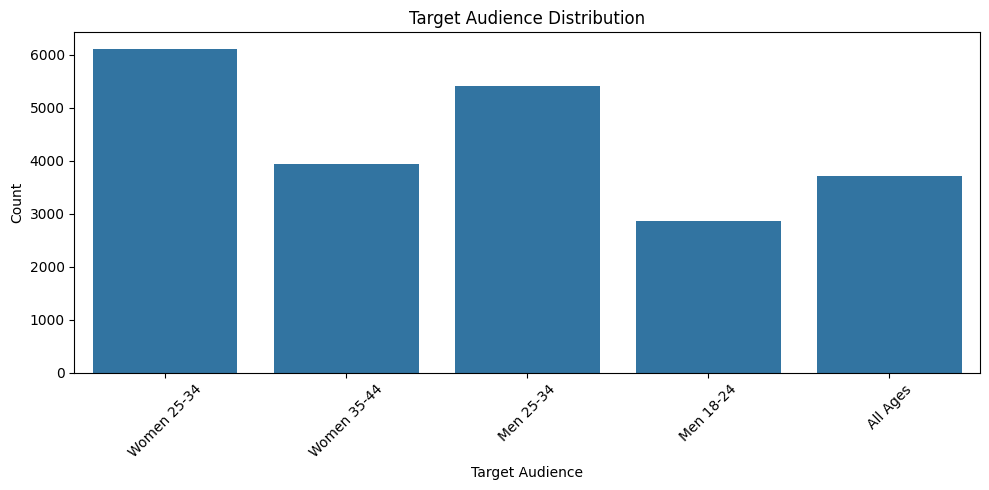

In [ ]:
#Count plot-Target Audience Distribution
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='Target_Audience')

plt.title('Target Audience Distribution')
plt.xlabel('Target Audience')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

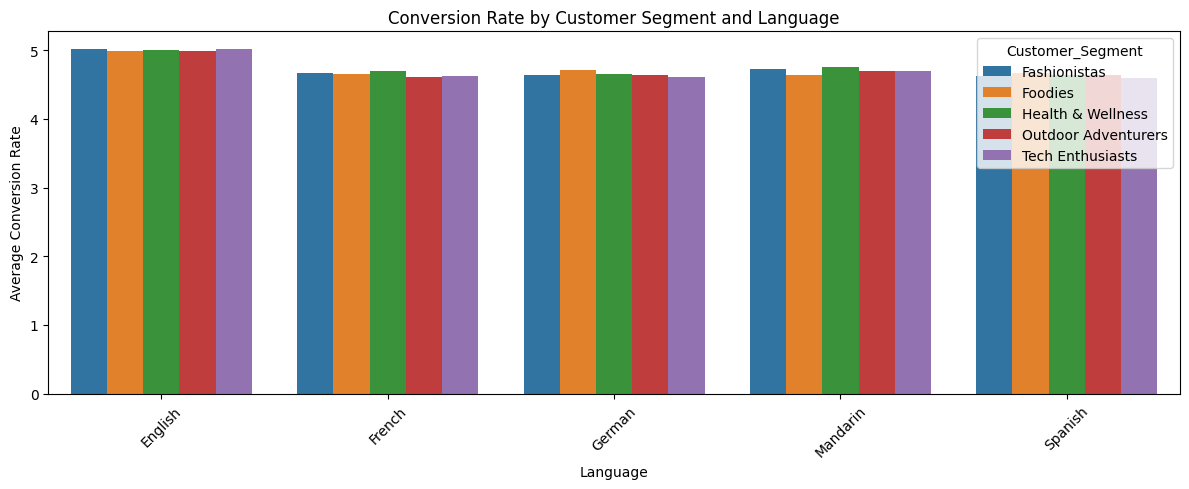

In [ ]:
#Barchart-Conversion Rate by Customer Segment and Language
segment_rate = df.groupby(['Language', 'Customer_Segment'])['Conversion_Rate'].mean().reset_index()

plt.figure(figsize=(12, 5))

sns.barplot(data=segment_rate,x='Language',y='Conversion_Rate',hue='Customer_Segment')

plt.title('Conversion Rate by Customer Segment and Language')
plt.xlabel('Language')
plt.ylabel('Average Conversion Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

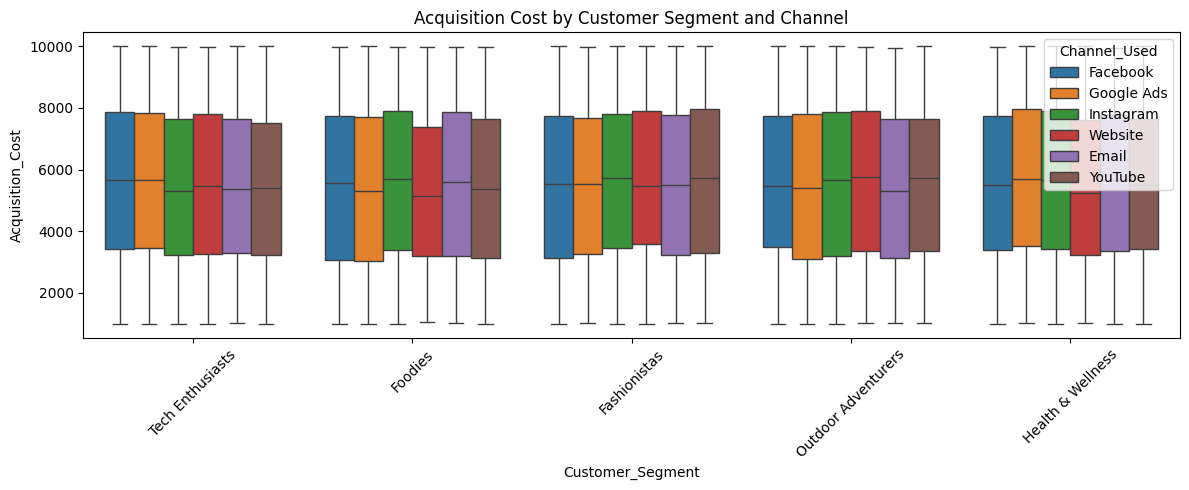

In [ ]:
#Box plot-Acquisition Cost by Customer Segment and Channel
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df,
    x='Customer_Segment',
    y='Acquisition_Cost',
    hue='Channel_Used'
)

plt.title('Acquisition Cost by Customer Segment and Channel')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

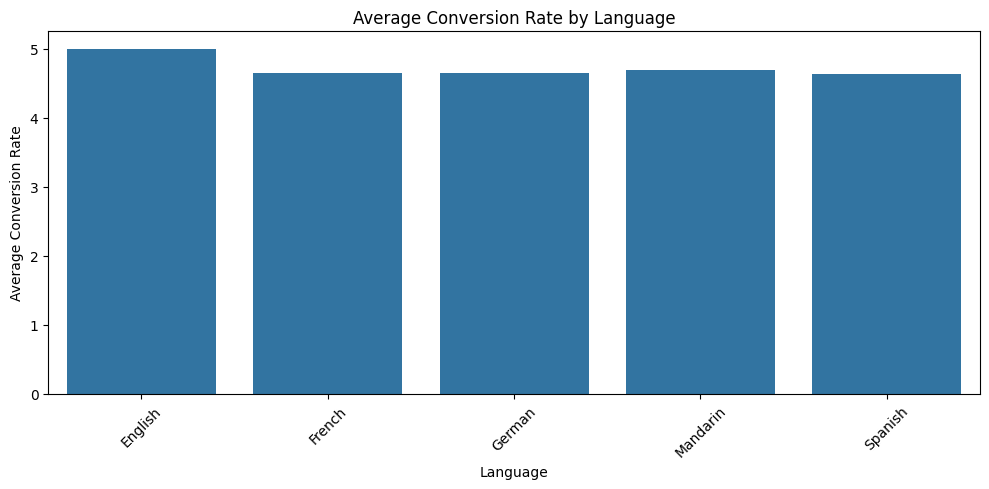

In [ ]:
#Barchart-Average Conversion Rate by Language
avg_conversion = df.groupby('Language')['Conversion_Rate'].mean().reset_index()

plt.figure(figsize=(10, 5))

sns.barplot(data=avg_conversion, x='Language', y='Conversion_Rate')

plt.title('Average Conversion Rate by Language')
plt.xlabel('Language')
plt.ylabel('Average Conversion Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3.Channel Effectiveness:

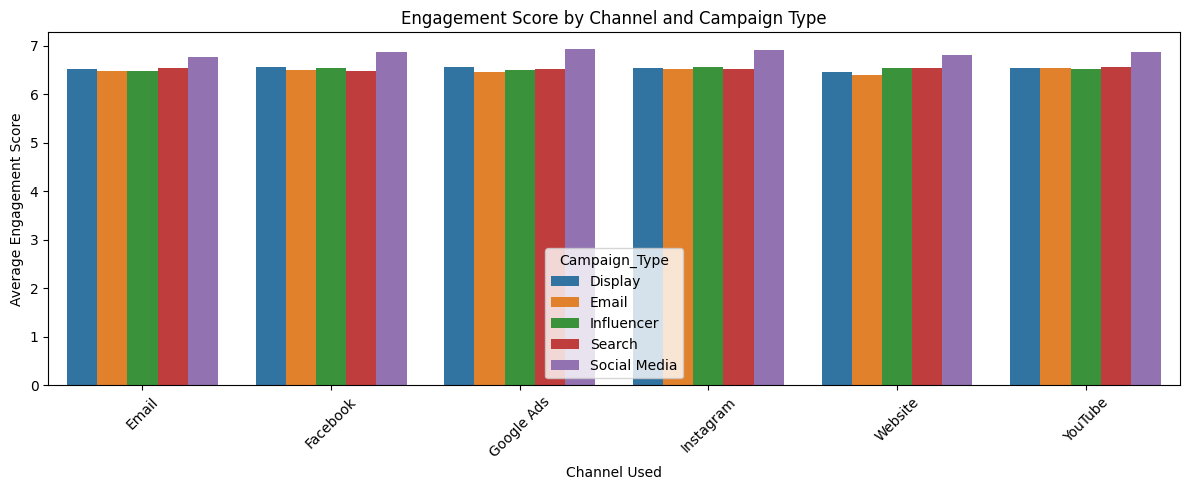

In [ ]:
#barchart-Engagement Score by Channel and Campaign Type
engagement = df.groupby(['Channel_Used', 'Campaign_Type'])['Engagement_Score'].mean().reset_index()
plt.figure(figsize=(12, 5))

sns.barplot(data=engagement,x='Channel_Used',y='Engagement_Score',hue='Campaign_Type')

plt.title('Engagement Score by Channel and Campaign Type')
plt.xlabel('Channel Used')
plt.ylabel('Average Engagement Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

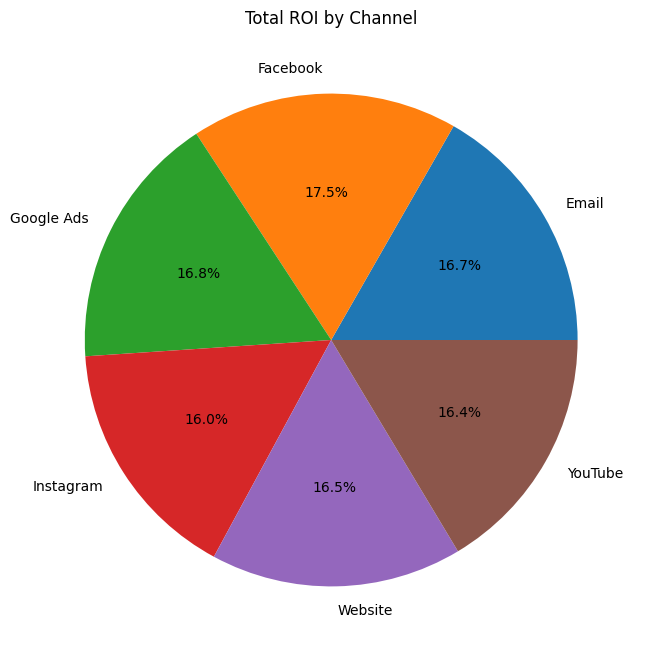

In [ ]:
#Pie chart-Total ROI by Channel
channel_roi = df.groupby('Channel_Used')['ROI'].sum()

plt.figure(figsize=(8, 8))

plt.pie(channel_roi,labels=channel_roi.index,autopct='%1.1f%%')

plt.title('Total ROI by Channel')
plt.show()

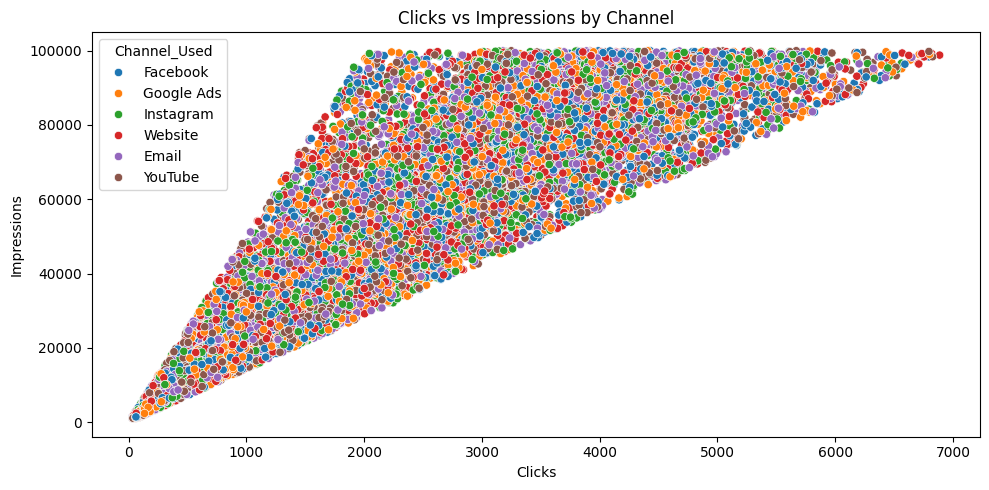

In [ ]:
#Scatter chart-Clicks vs Impressions by Channel
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='Clicks',
    y='Impressions',
    hue='Channel_Used'
)

plt.title('Clicks vs Impressions by Channel')
plt.xlabel('Clicks')
plt.ylabel('Impressions')
plt.tight_layout()
plt.show()

# 4. Time-Based Analysis:

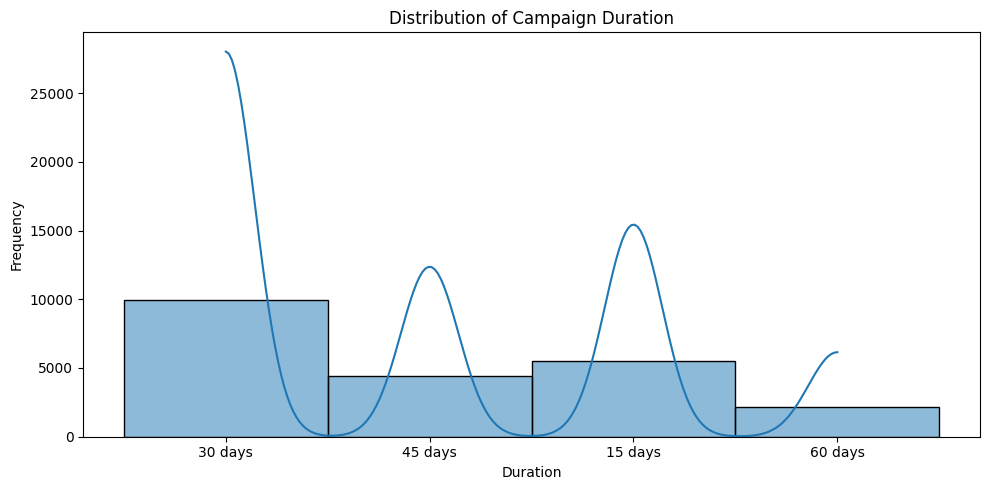

In [ ]:
#Histogram -Distribution of Campaign Duration
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Duration', bins=20, kde=True)

plt.title('Distribution of Campaign Duration')
plt.xlabel('Duration')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

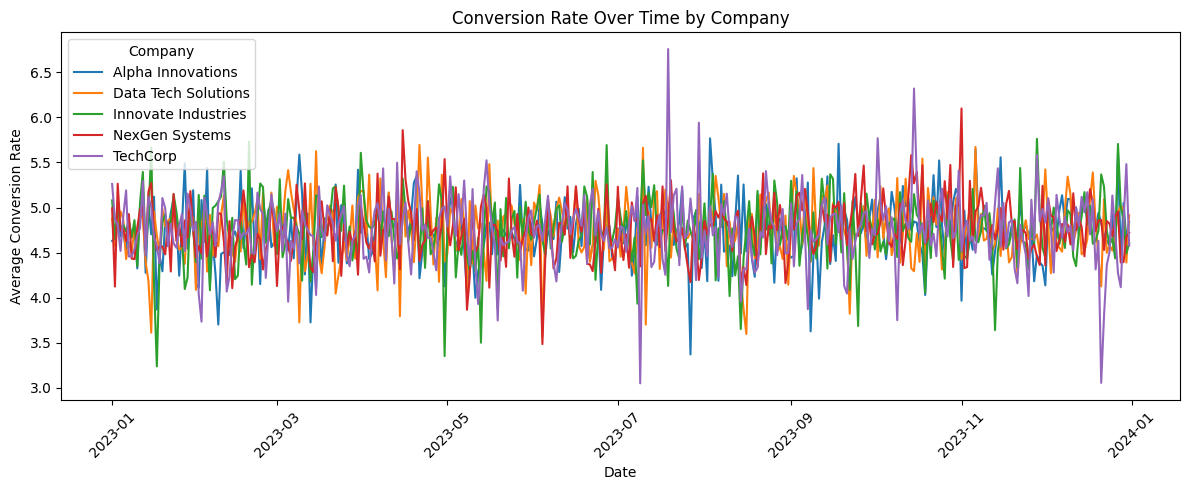

In [ ]:
#Line chart-Conversion Rate Over Time by Company
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

date_conversion = df.groupby(['Date', 'Company'])['Conversion_Rate'].mean().reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(data=date_conversion,x='Date', y='Conversion_Rate', hue='Company')

plt.title('Conversion Rate Over Time by Company')
plt.xlabel('Date')
plt.ylabel('Average Conversion Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

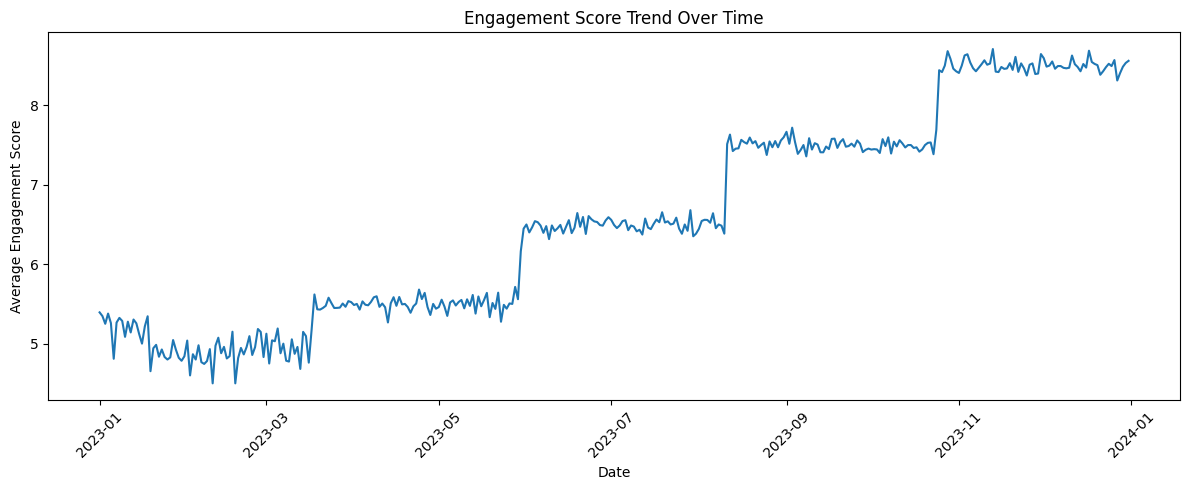

In [ ]:
#Line chart-Engagement Score Trend Over Time
date_engagement = df.groupby('Date')['Engagement_Score'].mean().reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(data=date_engagement, x='Date', y='Engagement_Score')

plt.title('Engagement Score Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Average Engagement Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. Geographic Analysis:

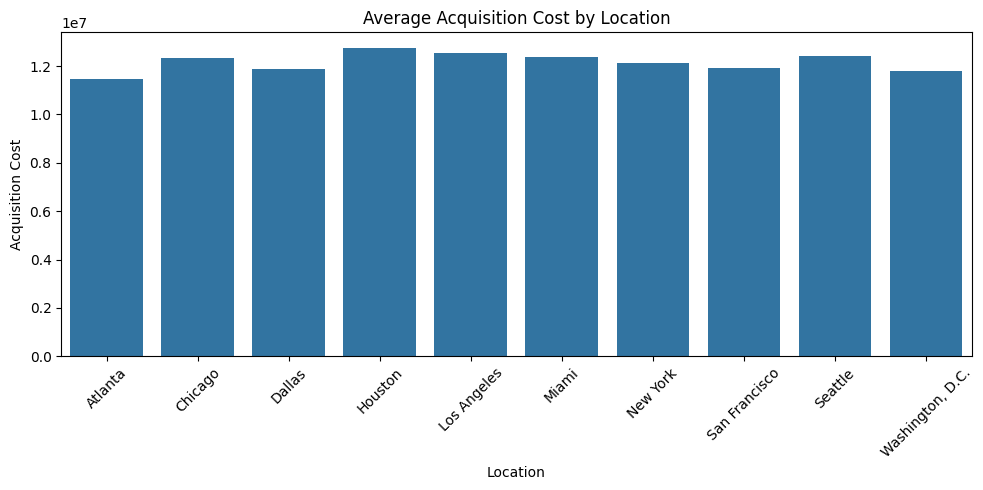

In [ ]:
#Bar chart-Average Acquisition Cost by Location
location_cost = df.groupby('Location')['Acquisition_Cost'].sum().reset_index()

plt.figure(figsize=(10, 5))

sns.barplot(data=location_cost, x='Location', y='Acquisition_Cost')

plt.title('Average Acquisition Cost by Location')
plt.xlabel('Location')
plt.ylabel('Acquisition Cost')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

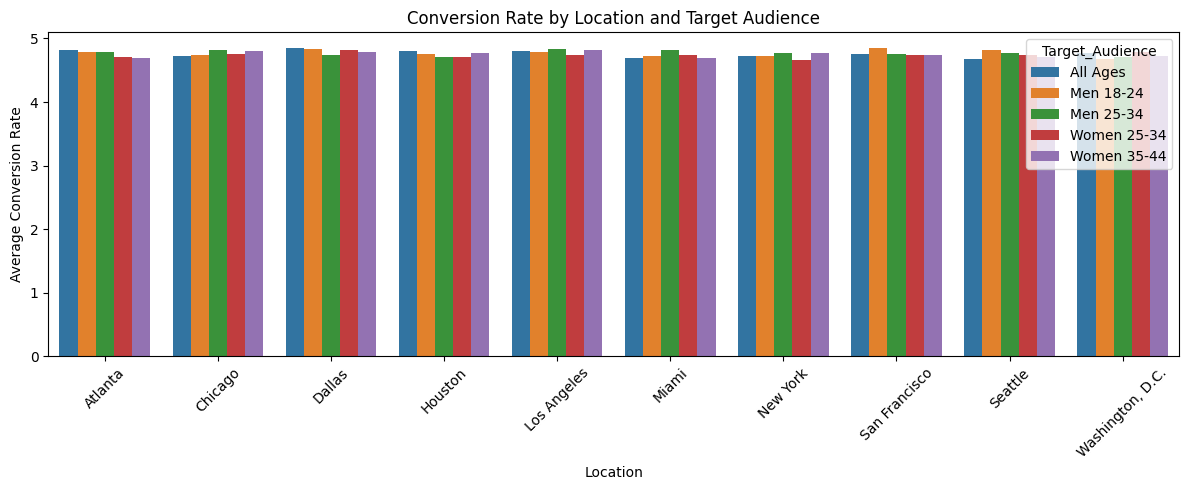

In [ ]:
#Bar chart-Conversion Rate by Location and Target Audience
location_conversion = df.groupby( ['Location', 'Target_Audience'])['Conversion_Rate'].mean().reset_index()

plt.figure(figsize=(12, 5))

sns.barplot(data=location_conversion,x='Location',y='Conversion_Rate',hue='Target_Audience')

plt.title('Conversion Rate by Location and Target Audience')
plt.xlabel('Location')
plt.ylabel('Average Conversion Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

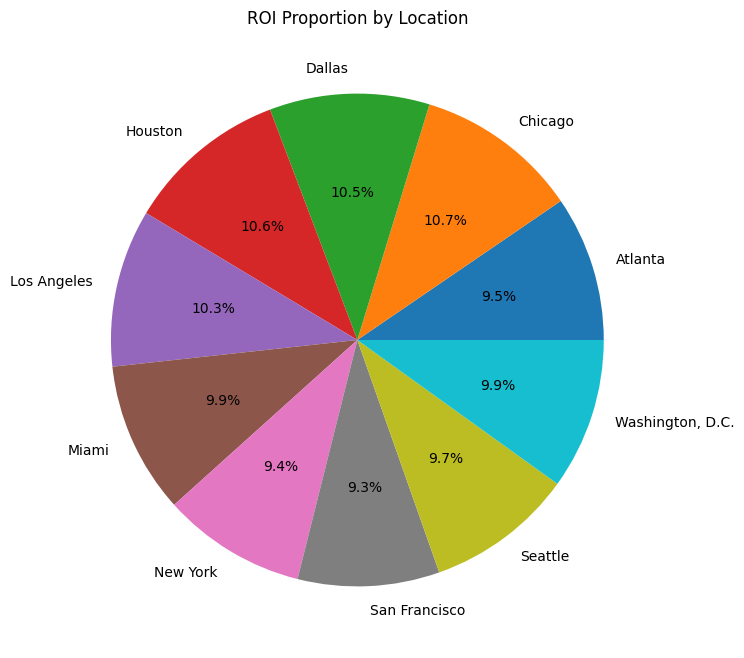

In [ ]:
#Pie chart-ROI Proportion by Location
location_roi = df.groupby('Location')['ROI'].sum()

plt.figure(figsize=(8, 8))

plt.pie(
    location_roi,
    labels=location_roi.index,
    autopct='%1.1f%%'
)

plt.title('ROI Proportion by Location')
plt.show()